<a href="https://colab.research.google.com/github/abdealimak/ML-CW/blob/main/Advertising_Sales_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Advertising Sales Prediction Using Machine Learning

**Dataset:** Advertising dataset (200 rows)
**Techniques:** EDA, Data Visualization, Linear Regression, Polynomial Regression, Logistic Regression

**Objective:** Study how money spent on TV, Radio and Newspaper advertising is related to product sales, and build regression and classification models to predict sales performance.

## Importing libraries

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, classification_report)

---
# Part A: Data Understanding and Preprocessing

## Q1. Load and explore the dataset

### 1. Import the dataset using Pandas

In [12]:
df = pd.read_csv('Advertising.csv')
df.head()

,Unnamed: 0,TV,radio,newspaper,sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


The csv has an extra column called `Unnamed: 0`. It is only the row number (1 to 200) and carries no information about advertising or sales, so I am dropping it. I am also renaming the columns so they match the names used in the assignment (TV, Radio, Newspaper, Sales).

In [13]:
df = df.drop(columns='Unnamed: 0')
df.columns = ['TV', 'Radio', 'Newspaper', 'Sales']
df.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


### 2. First 10 and last 10 records

In [14]:
print("First 10 records")
display(df.head(10))
print("Last 10 records")
display(df.tail(10))

First 10 records


,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9
5,8.7,48.9,75.0,7.2
6,57.5,32.8,23.5,11.8
7,120.2,19.6,11.6,13.2
8,8.6,2.1,1.0,4.8
9,199.8,2.6,21.2,10.6


Last 10 records


,TV,Radio,Newspaper,Sales
190,39.5,41.1,5.8,10.8
191,75.5,10.8,6.0,9.9
192,17.2,4.1,31.6,5.9
193,166.8,42.0,3.6,19.6
194,149.7,35.6,6.0,17.3
195,38.2,3.7,13.8,7.6
196,94.2,4.9,8.1,9.7
197,177.0,9.3,6.4,12.8
198,283.6,42.0,66.2,25.5
199,232.1,8.6,8.7,13.4


### 3. Total number of rows and columns

In [15]:
print("Rows   :", df.shape[0])
print("Columns:", df.shape[1])

Rows   : 200
Columns: 4


### 4. Independent and dependent variables

- Independent variables (features): TV, Radio, Newspaper
- Dependent variable (target): Sales

In [16]:
X = df[['TV', 'Radio', 'Newspaper']]
y = df['Sales']
print("Independent variables:", list(X.columns))
print("Dependent variable   :", y.name)

Independent variables: ['TV', 'Radio', 'Newspaper']
Dependent variable   : Sales


### 5. Missing values

In [17]:
df.isnull().sum()

,0
TV,0
Radio,0
Newspaper,0
Sales,0


There are no missing values in any column.

### 6. Duplicate records

In [18]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


No duplicate rows either.

### 7. Descriptive statistics

In [19]:
df.describe()

,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,14.022500
std,85.854236,14.846809,21.778621,5.217457
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,10.375000
50%,149.750000,22.900000,25.750000,12.900000
75%,218.825000,36.525000,45.100000,17.400000
max,296.400000,49.600000,114.000000,27.000000


### 8. Minimum, maximum, mean and standard deviation of each feature

In [20]:
summary = df.agg(['min', 'max', 'mean', 'std']).T
summary

,min,max,mean,std
TV,0.7,296.4,147.0425,85.854236
Radio,0.0,49.6,23.2640,14.846809
Newspaper,0.3,114.0,30.5540,21.778621
Sales,1.6,27.0,14.0225,5.217457


TV has the biggest spread in absolute terms (std about 85.9, range 0.7 to 296.4). Newspaper is the only column whose maximum (114) is far away from the rest of its values, which hints at outliers. This is checked next.

## Q2. Data preprocessing

### 1. Missing values
Already checked in Q1. The dataset has no missing values, so there is nothing to impute or drop.

In [21]:
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


### 2. Outliers using the IQR method

A value is treated as an outlier if it falls below Q1 - 1.5*IQR or above Q3 + 1.5*IQR.

In [22]:
for col in df.columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outliers = df[(df[col] < lower) | (df[col] > upper)]
    print(f"{col:10s} Q1={q1:7.2f}  Q3={q3:7.2f}  IQR={iqr:7.2f}  "
          f"lower={lower:8.2f}  upper={upper:8.2f}  outliers={len(outliers)}")

TV         Q1=  74.38  Q3= 218.82  IQR= 144.45  lower= -142.30  upper=  435.50  outliers=0
Radio      Q1=   9.97  Q3=  36.52  IQR=  26.55  lower=  -29.85  upper=   76.35  outliers=0
Newspaper  Q1=  12.75  Q3=  45.10  IQR=  32.35  lower=  -35.78  upper=   93.62  outliers=2
Sales      Q1=  10.38  Q3=  17.40  IQR=   7.02  lower=   -0.16  upper=   27.94  outliers=0


In [23]:
q1 = df['Newspaper'].quantile(0.25)
q3 = df['Newspaper'].quantile(0.75)
upper = q3 + 1.5 * (q3 - q1)
df[df['Newspaper'] > upper]

,TV,Radio,Newspaper,Sales
16,67.8,36.6,114.0,12.5
101,296.4,36.3,100.9,23.8


### 3. Preprocessing techniques

Only the Newspaper column has outliers, just 2 rows out of 200 (values of about 114 and 100). I decided to keep them because:

- They look like real, large newspaper campaigns and not data entry mistakes.
- Removing them would throw away 1% of an already small dataset.
- Linear and logistic regression are not hugely affected by just two points, and Newspaper has a very small effect on Sales anyway.

TV, Radio and Sales have no outliers. Apart from dropping the index column earlier, no other cleaning is needed. Scaling is also not required for linear regression since it is not distance based, but I will keep the scale of the features in mind when comparing coefficients in Q5.

### 4. Train-test split (80% train, 20% test)

In [24]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training set:", X_train.shape)
print("Testing set :", X_test.shape)

Training set: (160, 3)
Testing set : (40, 3)


### 5. Why do we need training and testing datasets?

The model is fitted on the training data, so it will naturally do well on data it has already seen. What we actually care about is how it performs on new data. By holding back 20% of the rows as a test set, which the model never sees during training, we get an honest estimate of its performance on unseen data. If we evaluated on the same data we trained on, we could not tell whether the model has really learnt the pattern or has just memorised the data (overfitting).

---
# Part B: Exploratory Data Analysis and Visualization

## Q3. Visualizations

### 1. Scatter plot: TV vs Sales

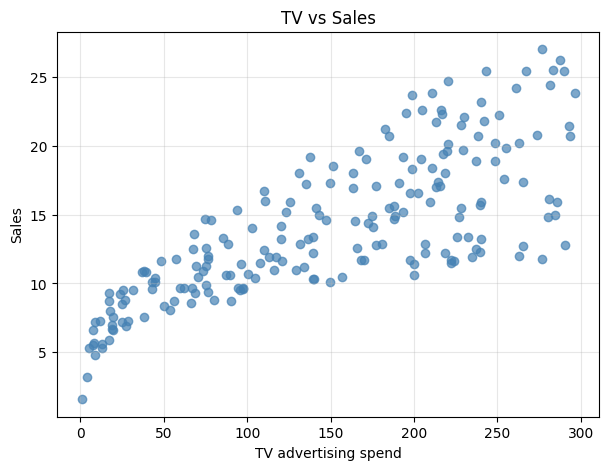

In [25]:
plt.figure(figsize=(7, 5))
plt.scatter(df['TV'], df['Sales'], color='steelblue', alpha=0.7)
plt.xlabel('TV advertising spend')
plt.ylabel('Sales')
plt.title('TV vs Sales')
plt.grid(alpha=0.3)
plt.show()

There is a clear positive relationship. As TV spend goes up, sales go up too, and the points follow a fairly tight upward trend. The spread of points gets wider at high TV spend though.

### 2. Scatter plot: Radio vs Sales

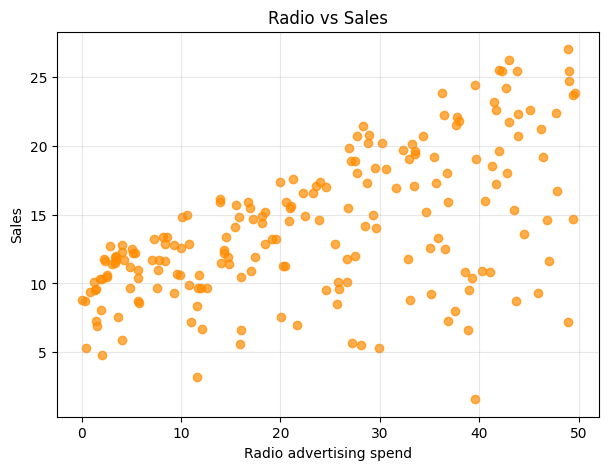

In [26]:
plt.figure(figsize=(7, 5))
plt.scatter(df['Radio'], df['Sales'], color='darkorange', alpha=0.7)
plt.xlabel('Radio advertising spend')
plt.ylabel('Sales')
plt.title('Radio vs Sales')
plt.grid(alpha=0.3)
plt.show()

Radio also has a positive relationship with sales, but it is noisier than TV. For the same radio spend there is a big range of sales values, so the relationship is moderate.

### 3. Scatter plot: Newspaper vs Sales

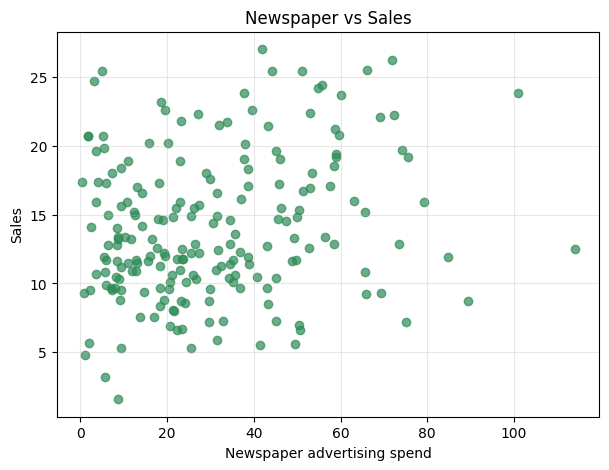

In [27]:
plt.figure(figsize=(7, 5))
plt.scatter(df['Newspaper'], df['Sales'], color='seagreen', alpha=0.7)
plt.xlabel('Newspaper advertising spend')
plt.ylabel('Sales')
plt.title('Newspaper vs Sales')
plt.grid(alpha=0.3)
plt.show()

The points are scattered all over the plot with almost no visible trend. Newspaper advertising has a weak relationship with sales.

### 4. Correlation heatmap

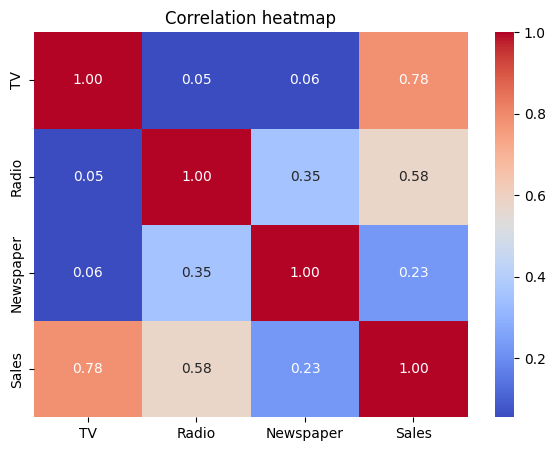

In [28]:
plt.figure(figsize=(7, 5))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation heatmap')
plt.show()

In [29]:
df.corr()['Sales'].drop('Sales').sort_values(ascending=False)

,Sales
TV,0.782224
Radio,0.576223
Newspaper,0.228299


TV has the strongest correlation with Sales (0.78), followed by Radio (0.58) and Newspaper (0.23).

### 5. Histograms

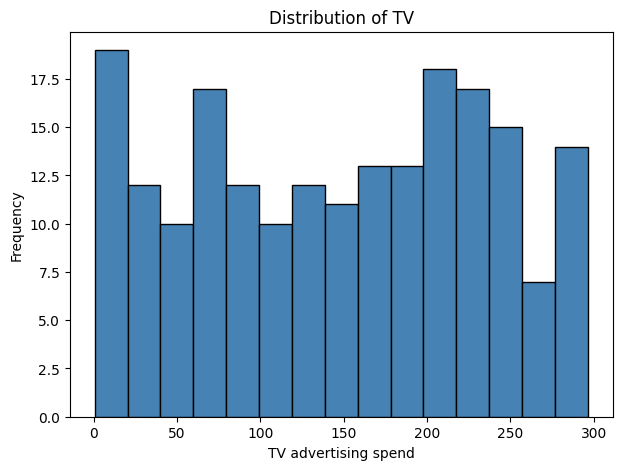

In [30]:
plt.figure(figsize=(7, 5))
plt.hist(df['TV'], bins=15, color='steelblue', edgecolor='black')
plt.xlabel('TV advertising spend')
plt.ylabel('Frequency')
plt.title('Distribution of TV')
plt.show()

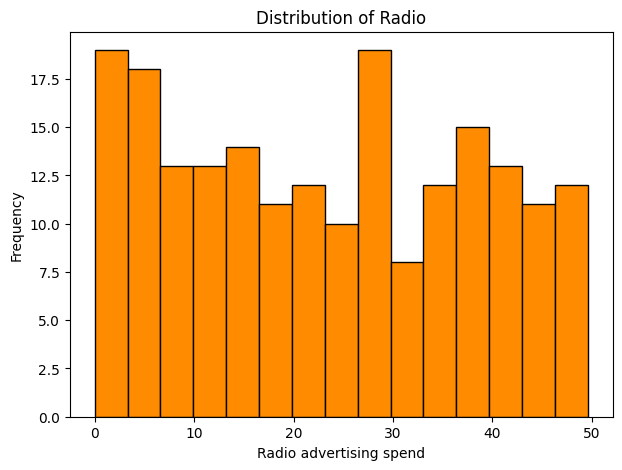

In [31]:
plt.figure(figsize=(7, 5))
plt.hist(df['Radio'], bins=15, color='darkorange', edgecolor='black')
plt.xlabel('Radio advertising spend')
plt.ylabel('Frequency')
plt.title('Distribution of Radio')
plt.show()

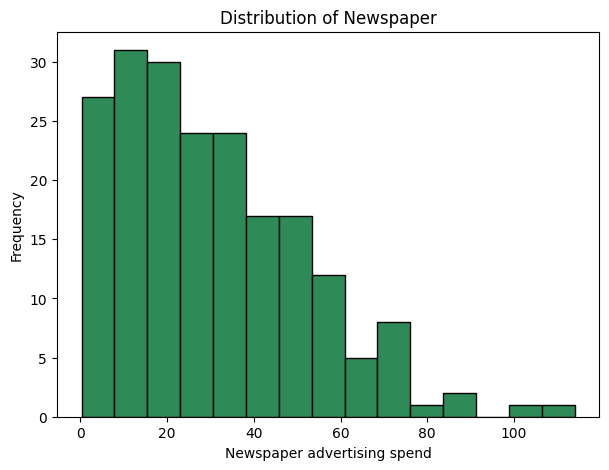

In [32]:
plt.figure(figsize=(7, 5))
plt.hist(df['Newspaper'], bins=15, color='seagreen', edgecolor='black')
plt.xlabel('Newspaper advertising spend')
plt.ylabel('Frequency')
plt.title('Distribution of Newspaper')
plt.show()

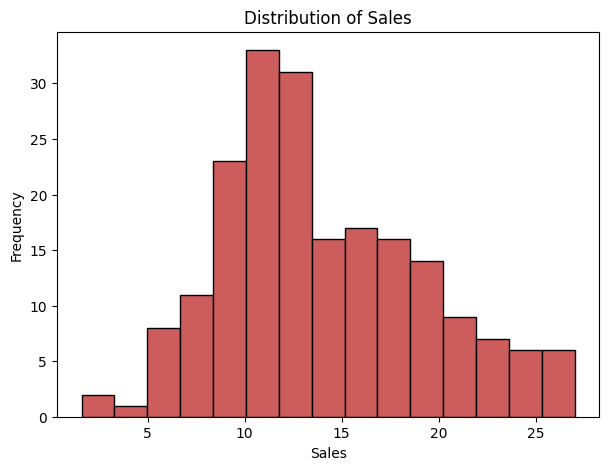

In [33]:
plt.figure(figsize=(7, 5))
plt.hist(df['Sales'], bins=15, color='indianred', edgecolor='black')
plt.xlabel('Sales')
plt.ylabel('Frequency')
plt.title('Distribution of Sales')
plt.show()

In [34]:
df.skew()

,0
TV,-0.069853
Radio,0.094175
Newspaper,0.894720
Sales,0.407571


TV and Radio are spread fairly evenly across their ranges (roughly flat, skewness close to zero). Newspaper is right skewed (skewness about 0.89), most values are low with a long tail towards high spends. Sales looks roughly bell shaped with a slight right skew, with most values between 10 and 18.

### 6. Box plots

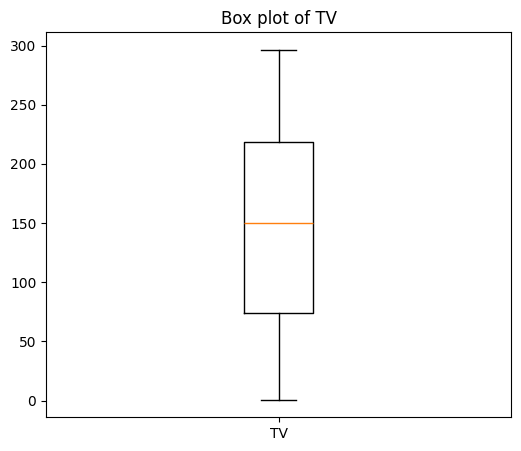

In [35]:
plt.figure(figsize=(6, 5))
plt.boxplot(df['TV'])
plt.xticks([1], ['TV'])
plt.title('Box plot of TV')
plt.show()

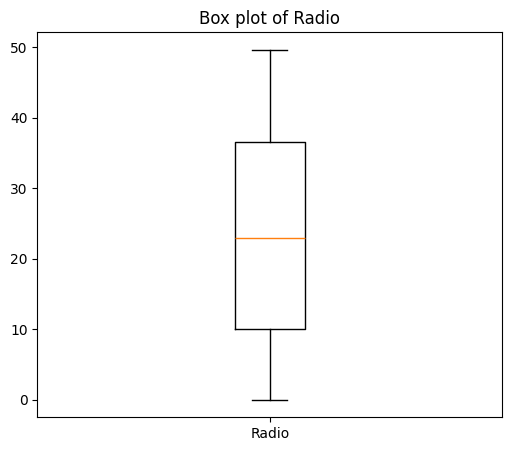

In [36]:
plt.figure(figsize=(6, 5))
plt.boxplot(df['Radio'])
plt.xticks([1], ['Radio'])
plt.title('Box plot of Radio')
plt.show()

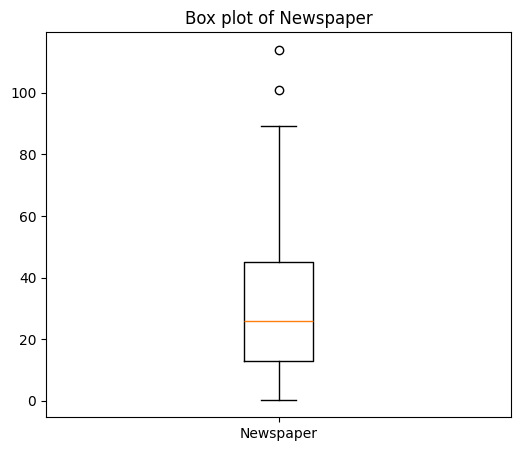

In [37]:
plt.figure(figsize=(6, 5))
plt.boxplot(df['Newspaper'])
plt.xticks([1], ['Newspaper'])
plt.title('Box plot of Newspaper')
plt.show()

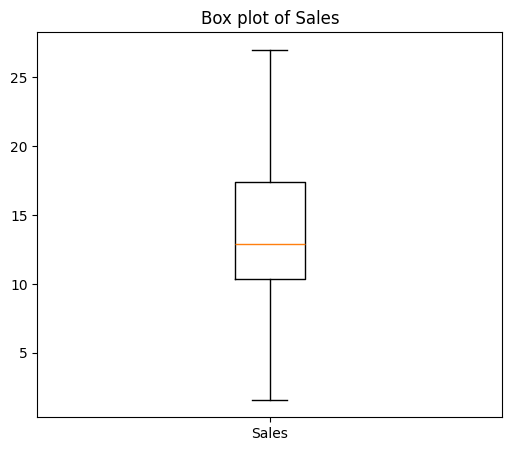

In [38]:
plt.figure(figsize=(6, 5))
plt.boxplot(df['Sales'])
plt.xticks([1], ['Sales'])
plt.title('Box plot of Sales')
plt.show()

Only Newspaper shows outliers (two points above the upper whisker). TV, Radio and Sales have none, which matches the IQR result in Q2.

### Analytical questions

In [39]:
# supporting numbers for the answers below
print("Correlation with Sales:")
print(df.corr()['Sales'].drop('Sales').round(3))
print()
print("Standard deviation:")
print(df.std().round(2))
print()
print("Coefficient of variation (std / mean):")
print((df.std() / df.mean()).round(2))
print()
print("Correlation between TV and Radio:", round(df['TV'].corr(df['Radio']), 3))
print("R-squared of TV alone vs Sales  :", round(df['TV'].corr(df['Sales']) ** 2, 3))

Correlation with Sales:
TV           0.782
Radio        0.576
Newspaper    0.228
Name: Sales, dtype: float64

Standard deviation:
TV           85.85
Radio        14.85
Newspaper    21.78
Sales         5.22
dtype: float64

Coefficient of variation (std / mean):
TV           0.58
Radio        0.64
Newspaper    0.71
Sales        0.37
dtype: float64

Correlation between TV and Radio: 0.055
R-squared of TV alone vs Sales  : 0.612


**1. Which advertising medium has the strongest relationship with sales?**
TV. Its correlation with Sales is 0.78, the highest of the three.

**2. Which advertising medium has the weakest relationship with sales?**
Newspaper, with a correlation of only 0.23.

**3. Does spending more money on TV advertising always result in higher sales?**
No. The trend is upward overall, but TV spend alone explains only about 61% of the variation in sales (0.78 squared). In the scatter plot, the points get more spread out at high TV spend, so two campaigns with a similar high budget can give quite different sales. Other factors, like radio spend, also matter.

**4. Which feature has the highest variation?**
In absolute terms, TV has the highest standard deviation (about 85.9). If we compare relative variation (std divided by mean), Newspaper is the highest (about 0.71) because its values are small on average but have a long tail.

**5. Are there any outliers in advertising expenditure?**
Yes, only in Newspaper (2 values above the upper limit of about 93). TV and Radio have none.

**6. Can you identify any relationship between TV and Radio advertising?**
No. Their correlation is only about 0.05, so they are essentially independent. Companies in this data did not tend to raise one when they raised the other. (Radio and Newspaper have a mild correlation of 0.35.)

---
# Part C: Linear Regression

## Q4. Simple Linear Regression (TV vs Sales)

### 1 and 2. Independent variable is TV, dependent variable is Sales, and the data is split into train and test sets

In [40]:
X_tv = df[['TV']]

X_train_tv, X_test_tv, y_train_tv, y_test_tv = train_test_split(
    X_tv, y, test_size=0.2, random_state=42)

print("Train:", X_train_tv.shape, " Test:", X_test_tv.shape)

Train: (160, 1)  Test: (40, 1)


### 3. Train the model

In [41]:
lin_model = LinearRegression()
lin_model.fit(X_train_tv, y_train_tv)

LinearRegression()

### 4. Intercept and coefficient

In [42]:
intercept = lin_model.intercept_
coef = lin_model.coef_[0]
print("Intercept  :", round(intercept, 4))
print("Coefficient:", round(coef, 4))

Intercept  : 7.1196
Coefficient: 0.0465


### 5. Regression equation

In [43]:
print(f"Sales = {intercept:.4f} + {coef:.4f} * TV")

Sales = 7.1196 + 0.0465 * TV


So with zero TV spend the model predicts sales of about 7.12 units, and every extra unit of TV spend adds about 0.0465 to sales (for example, 100 more units of TV spend increases sales by about 4.65).

### 6. Predict sales for the test set

In [44]:
y_pred_tv = lin_model.predict(X_test_tv)

comparison = pd.DataFrame({'Actual': y_test_tv.values, 'Predicted': y_pred_tv.round(2)})
comparison.head(10)

,Actual,Predicted
0,16.9,14.72
1,22.4,16.21
2,21.4,20.75
3,7.3,7.66
4,24.7,17.37
5,12.6,10.61
6,22.3,17.21
7,8.4,9.45
8,11.5,17.47
9,14.9,15.27


### 7. Actual vs predicted

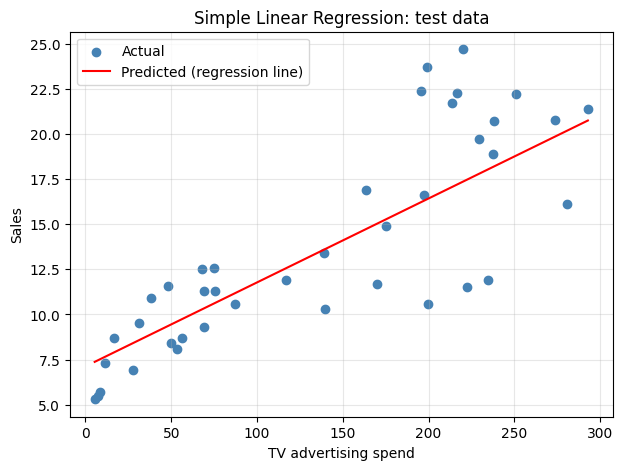

In [45]:
# regression line on the test data
order = np.argsort(X_test_tv['TV'].values)
plt.figure(figsize=(7, 5))
plt.scatter(X_test_tv, y_test_tv, color='steelblue', label='Actual')
plt.plot(X_test_tv['TV'].values[order], y_pred_tv[order], color='red', label='Predicted (regression line)')
plt.xlabel('TV advertising spend')
plt.ylabel('Sales')
plt.title('Simple Linear Regression: test data')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

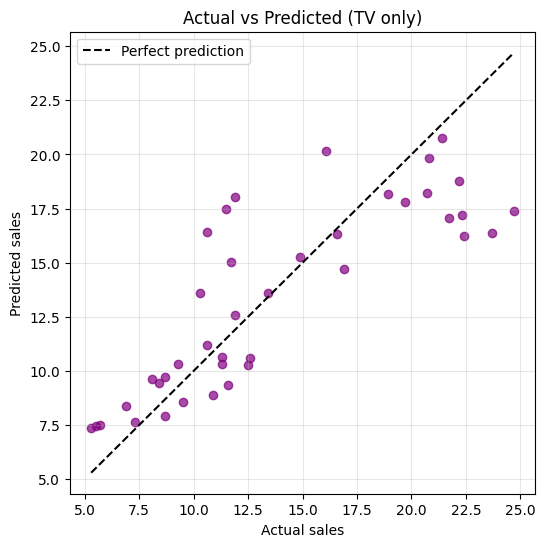

In [46]:
# actual vs predicted values directly
plt.figure(figsize=(6, 6))
plt.scatter(y_test_tv, y_pred_tv, color='purple', alpha=0.7)
plt.plot([y_test_tv.min(), y_test_tv.max()], [y_test_tv.min(), y_test_tv.max()], 'k--', label='Perfect prediction')
plt.xlabel('Actual sales')
plt.ylabel('Predicted sales')
plt.title('Actual vs Predicted (TV only)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

The points are scattered quite a bit around the dashed line, so the TV-only model is only moderately accurate.

## Q5. Multiple Linear Regression

### 1 and 2. Independent variables are TV, Radio and Newspaper, dependent variable is Sales
We reuse the same 80/20 split made in Q2 (`X_train`, `X_test`, `y_train`, `y_test`), so the comparison with the simple model is fair.

### 3. Train the model

In [47]:
mlr_model = LinearRegression()
mlr_model.fit(X_train, y_train)

LinearRegression()

### 4. Coefficients

In [48]:
print("Intercept:", round(mlr_model.intercept_, 4))
coef_df = pd.DataFrame({'Feature': X.columns, 'Coefficient': mlr_model.coef_})
coef_df

Intercept: 2.9791


,Feature,Coefficient
0,TV,0.044730
1,Radio,0.189195
2,Newspaper,0.002761


In [49]:
print(f"Sales = {mlr_model.intercept_:.4f} + {mlr_model.coef_[0]:.4f}*TV "
      f"+ {mlr_model.coef_[1]:.4f}*Radio + {mlr_model.coef_[2]:.4f}*Newspaper")

Sales = 2.9791 + 0.0447*TV + 0.1892*Radio + 0.0028*Newspaper


### 5. Which medium contributes most?

Looking at the raw coefficients alone, Radio (0.189) looks the biggest, but that is misleading because the features are on different scales. A one unit change in Radio is a much bigger move than a one unit change in TV (Radio std is about 15 while TV std is about 86). To compare fairly, I multiply each coefficient by the standard deviation of its feature. This tells us how much Sales changes for a one standard deviation increase in that medium.

In [50]:
effect = mlr_model.coef_ * X_train.std().values
pd.DataFrame({'Feature': X.columns,
              'Raw coefficient': mlr_model.coef_,
              'Std of feature': X_train.std().values,
              'Coef x Std': effect})

,Feature,Raw coefficient,Std of feature,Coef x Std
0,TV,0.044730,84.418857,3.776015
1,Radio,0.189195,14.805216,2.801074
2,Newspaper,0.002761,20.336449,0.056151


After adjusting for scale, TV contributes the most (about 3.8 sales units per std), then Radio (about 2.8), while Newspaper is almost zero (about 0.06). So TV is the biggest contributor, Radio is second, and Newspaper adds practically nothing once TV and Radio are in the model.

### 6. Compare simple and multiple linear regression

In [51]:
y_pred_mlr = mlr_model.predict(X_test)

def get_metrics(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    mse = mean_squared_error(actual, predicted)
    rmse = np.sqrt(mse)
    r2 = r2_score(actual, predicted)
    return [mae, mse, rmse, r2]

lin_results = pd.DataFrame(
    {'Simple LR (TV)': get_metrics(y_test_tv, y_pred_tv),
     'Multiple LR (TV, Radio, Newspaper)': get_metrics(y_test, y_pred_mlr)},
    index=['MAE', 'MSE', 'RMSE', 'R2'])
lin_results.round(4)

,Simple LR (TV),"Multiple LR (TV, Radio, Newspaper)"
MAE,2.4444,1.4608
MSE,10.2047,3.1741
RMSE,3.1945,1.7816
R2,0.6767,0.8994


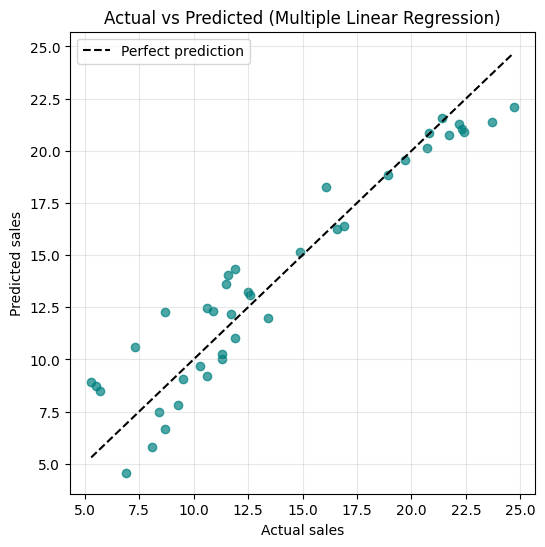

In [52]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred_mlr, color='teal', alpha=0.7)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', label='Perfect prediction')
plt.xlabel('Actual sales')
plt.ylabel('Predicted sales')
plt.title('Actual vs Predicted (Multiple Linear Regression)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Here the points sit much closer to the dashed line than they did for the TV-only model, so the multiple regression is clearly better.

## Q6. Model evaluation (MAE, MSE, RMSE, R2)

The metrics for both models are in the table above (computed on the test set):

| Metric | Simple LR | Multiple LR |
|---|---|---|
| MAE | 2.444 | 1.461 |
| MSE | 10.205 | 3.174 |
| RMSE | 3.194 | 1.782 |
| R2 | 0.677 | 0.899 |

**1. Which model performs better?**
Multiple Linear Regression. All the error measures are much lower (RMSE drops from 3.19 to 1.78) and R2 rises from 0.68 to 0.90.

**2. What does the R2 score indicate?**
R2 tells us what fraction of the variation in Sales is explained by the model. An R2 of 0.90 means the model explains about 90% of the variation in sales in the test data. 1 would be a perfect fit and 0 means the model is no better than just predicting the average sales every time.

**3. Why does Multiple Linear Regression use more than one independent variable?**
Sales is influenced by more than one thing. A model with only TV ignores the effect of Radio (and Newspaper), so a lot of the variation stays unexplained. Using several predictors lets the model account for each of them at the same time, which improves accuracy, and it also tells us the effect of each medium while the others are held constant.

---
# Part D: Polynomial Regression

## Q7. Polynomial Regression on TV vs Sales

### 1 and 2. Independent variable is TV, dependent variable is Sales
The same train/test split from Q4 is used.

### 3 and 4. Degree 2 polynomial regression

In [53]:
poly2 = PolynomialFeatures(degree=2)
X_train_p2 = poly2.fit_transform(X_train_tv)
X_test_p2 = poly2.transform(X_test_tv)

poly_model2 = LinearRegression()
poly_model2.fit(X_train_p2, y_train_tv)

y_train_pred2 = poly_model2.predict(X_train_p2)
y_test_pred2 = poly_model2.predict(X_test_p2)

print("Intercept   :", round(poly_model2.intercept_, 4))
print("Coefficients:", poly_model2.coef_.round(6))

Intercept   : 6.1408
Coefficients: [ 0.0000e+00  6.6604e-02 -6.9000e-05]


### 5. Degree 3 polynomial regression

In [54]:
poly3 = PolynomialFeatures(degree=3)
X_train_p3 = poly3.fit_transform(X_train_tv)
X_test_p3 = poly3.transform(X_test_tv)

poly_model3 = LinearRegression()
poly_model3.fit(X_train_p3, y_train_tv)

y_train_pred3 = poly_model3.predict(X_train_p3)
y_test_pred3 = poly_model3.predict(X_test_p3)

print("Intercept   :", round(poly_model3.intercept_, 4))
print("Coefficients:", poly_model3.coef_)

Intercept   : 5.0728
Coefficients: [ 0.00000000e+00  1.10650495e-01 -4.39409614e-04  8.34140389e-07]


### 6. Original data points and predicted curves

In [55]:
# smooth range of TV values to draw the curves
tv_range = pd.DataFrame({'TV': np.linspace(df['TV'].min(), df['TV'].max(), 200)})
curve2 = poly_model2.predict(poly2.transform(tv_range))
curve3 = poly_model3.predict(poly3.transform(tv_range))

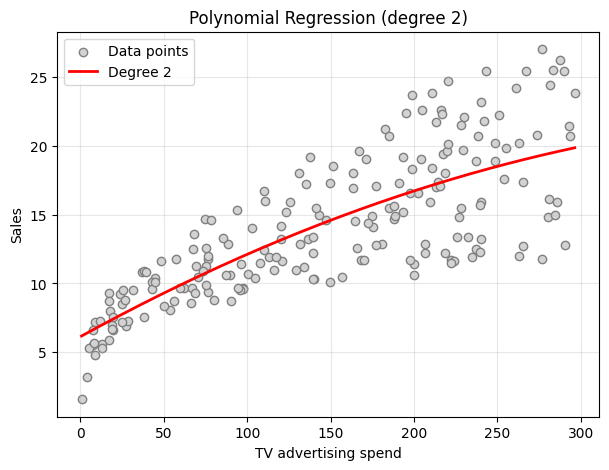

In [56]:
plt.figure(figsize=(7, 5))
plt.scatter(df['TV'], df['Sales'], color='lightgray', edgecolor='gray', label='Data points')
plt.plot(tv_range['TV'], curve2, color='red', linewidth=2, label='Degree 2')
plt.xlabel('TV advertising spend')
plt.ylabel('Sales')
plt.title('Polynomial Regression (degree 2)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

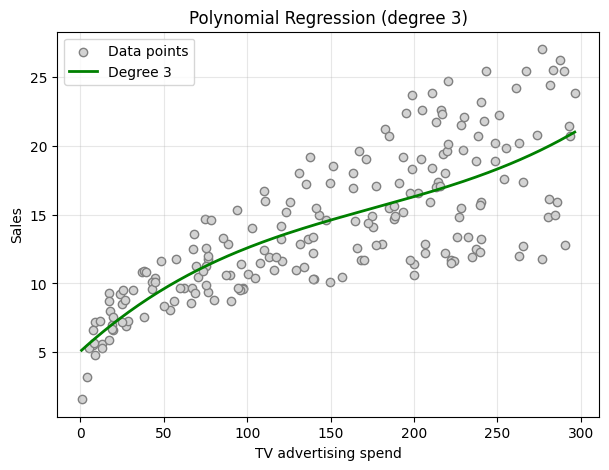

In [57]:
plt.figure(figsize=(7, 5))
plt.scatter(df['TV'], df['Sales'], color='lightgray', edgecolor='gray', label='Data points')
plt.plot(tv_range['TV'], curve3, color='green', linewidth=2, label='Degree 3')
plt.xlabel('TV advertising spend')
plt.ylabel('Sales')
plt.title('Polynomial Regression (degree 3)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 7. MAE, MSE, RMSE and R2 for both models

In [58]:
poly_results = pd.DataFrame(
    {'Degree 2 (test)': get_metrics(y_test_tv, y_test_pred2),
     'Degree 3 (test)': get_metrics(y_test_tv, y_test_pred3),
     'Degree 2 (train)': get_metrics(y_train_tv, y_train_pred2),
     'Degree 3 (train)': get_metrics(y_train_tv, y_train_pred3)},
    index=['MAE', 'MSE', 'RMSE', 'R2'])
poly_results.round(4)

,Degree 2 (test),Degree 3 (test),Degree 2 (train),Degree 3 (train)
MAE,2.4517,2.4598,2.5865,2.5727
MSE,10.0201,10.4302,10.4056,10.2299
RMSE,3.1655,3.2296,3.2258,3.1984
R2,0.6825,0.6695,0.5988,0.6056


I have shown the train metrics as well, since they are needed to talk about overfitting in Q8.

## Q8. Comparative analysis

In [59]:
compare = pd.DataFrame(
    {'Linear (TV)': get_metrics(y_test_tv, y_pred_tv),
     'Poly degree 2': get_metrics(y_test_tv, y_test_pred2),
     'Poly degree 3': get_metrics(y_test_tv, y_test_pred3)},
    index=['MAE', 'MSE', 'RMSE', 'R2'])
compare.round(4)

,Linear (TV),Poly degree 2,Poly degree 3
MAE,2.4444,2.4517,2.4598
MSE,10.2047,10.0201,10.4302
RMSE,3.1945,3.1655,3.2296
R2,0.6767,0.6825,0.6695


In [60]:
# train vs test R2 for each TV-only model
print("Train R2 - Linear   :", round(r2_score(y_train_tv, lin_model.predict(X_train_tv)), 4))
print("Train R2 - Degree 2 :", round(r2_score(y_train_tv, y_train_pred2), 4))
print("Train R2 - Degree 3 :", round(r2_score(y_train_tv, y_train_pred3), 4))
print()
print("Test R2  - Linear   :", round(r2_score(y_test_tv, y_pred_tv), 4))
print("Test R2  - Degree 2 :", round(r2_score(y_test_tv, y_test_pred2), 4))
print("Test R2  - Degree 3 :", round(r2_score(y_test_tv, y_test_pred3), 4))

Train R2 - Linear   : 0.5912
Train R2 - Degree 2 : 0.5988
Train R2 - Degree 3 : 0.6056

Test R2  - Linear   : 0.6767
Test R2  - Degree 2 : 0.6825
Test R2  - Degree 3 : 0.6695


**1. Compare Linear Regression and Polynomial Regression.**
Linear regression fits a straight line, so it assumes each extra unit of TV spend adds the same amount of sales. Polynomial regression adds squared (and cubed) terms so the fitted line can bend. On this data the three TV-only models perform very similarly (test R2 of 0.677, 0.683 and 0.670 for linear, degree 2 and degree 3).

**2. Does Polynomial Regression perform better than Linear Regression?**
Only marginally. Degree 2 is a tiny bit better on the test set (R2 0.683 vs 0.677, RMSE 3.17 vs 3.19), which is such a small difference that it could easily be down to the particular train/test split. Degree 3 is actually slightly worse than the linear model on the test set. So polynomial terms do not give a meaningful improvement here, which makes sense because the TV vs Sales scatter plot is already close to a straight line (with just a slight curve).

**3. What happens when the polynomial degree increases?**
The curve becomes more flexible and can bend to follow more of the points. The training fit keeps getting a bit better (train R2 goes from about 0.60 for degree 2 to 0.61 for degree 3), but the test performance stopped improving and went down (0.683 to 0.670). A higher degree also means more coefficients to estimate and a higher risk of fitting noise.

**4. Explain overfitting with reference to your results.**
Overfitting is when a model learns the noise of the training data instead of the general pattern, so it does well on training data but worse on new data. In our results, going from degree 2 to degree 3 improved the train R2 but lowered the test R2, which is the early sign of overfitting. It is mild here because degree 3 is still a fairly simple curve and the dataset is small, but if we kept increasing the degree the gap between train and test scores would keep growing.

**5. Which model would you recommend for predicting sales?**
Among the TV-only models, I would pick the simple linear regression (or degree 2 at most), because it is simpler and just as accurate. But better than all of them is the Multiple Linear Regression from Q5 (R2 0.90), since adding Radio improves predictions far more than adding polynomial terms to TV does.

---
# Part E: Logistic Regression

## Q9. Converting to a classification problem

### 1. Create the binary target variable
Sales >= 15 is High Sales (1), otherwise Low Sales (0).

In [61]:
df['Sales_Category'] = np.where(df['Sales'] >= 15, 1, 0)
df[['Sales', 'Sales_Category']].head(10)

,Sales,Sales_Category
0,22.1,1
1,10.4,0
2,9.3,0
3,18.5,1
4,12.9,0
5,7.2,0
6,11.8,0
7,13.2,0
8,4.8,0
9,10.6,0


### 2. Number of High Sales and Low Sales observations

In [62]:
counts = df['Sales_Category'].value_counts()
print("High Sales (1):", counts[1])
print("Low Sales  (0):", counts[0])

High Sales (1): 77
Low Sales  (0): 123


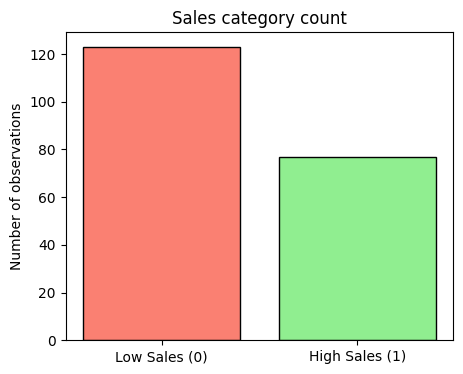

In [63]:
plt.figure(figsize=(5, 4))
plt.bar(['Low Sales (0)', 'High Sales (1)'], [counts[0], counts[1]], color=['salmon', 'lightgreen'], edgecolor='black')
plt.ylabel('Number of observations')
plt.title('Sales category count')
plt.show()

There are 123 low sales and 77 high sales observations, so the classes are a bit imbalanced (about 62% vs 38%) but not severely.

### 3 and 4. Independent variables and train-test split

TV, Radio and Newspaper are the features. I use `stratify` in the split so that the proportion of high and low sales is the same in both the train and test sets, which is a good idea since the classes are not balanced.

In [64]:
X_clf = df[['TV', 'Radio', 'Newspaper']]
y_clf = df['Sales_Category']

Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=42, stratify=y_clf)

print("Train:", Xc_train.shape, " Test:", Xc_test.shape)
print("High sales in test set:", yc_test.sum(), "of", len(yc_test))

Train: (160, 3)  Test: (40, 3)
High sales in test set: 15 of 40


### 5. Train the Logistic Regression model

In [65]:
log_model = LogisticRegression(max_iter=1000)
log_model.fit(Xc_train, yc_train)

print("Intercept   :", log_model.intercept_.round(4))
print("Coefficients:", dict(zip(X_clf.columns, log_model.coef_[0].round(4))))

Intercept   : [-27.249]
Coefficients: {'TV': np.float64(0.0872), 'Radio': np.float64(0.4862), 'Newspaper': np.float64(0.0049)}


### 6. Predict High or Low sales

In [66]:
yc_pred = log_model.predict(Xc_test)
yc_prob = log_model.predict_proba(Xc_test)[:, 1]

pred_df = pd.DataFrame({'Actual': yc_test.values,
                        'Predicted': yc_pred,
                        'Prob of High Sales': yc_prob.round(3)})
pred_df.head(10)

,Actual,Predicted,Prob of High Sales
0,0,0,0.043
1,0,0,0.001
2,1,1,1.000
3,0,0,0.000
4,1,1,1.000
5,0,0,0.001
6,1,0,0.243
7,0,0,0.001
8,1,1,1.000
9,1,1,1.000


### 7. Confusion matrix

In [67]:
cm = confusion_matrix(yc_test, yc_pred)
print(cm)

[[22  3]
 [ 2 13]]


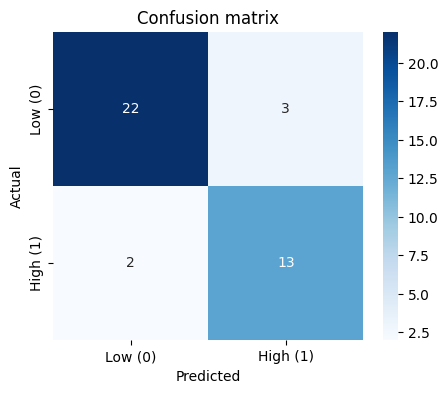

In [68]:
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Low (0)', 'High (1)'], yticklabels=['Low (0)', 'High (1)'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion matrix')
plt.show()

Out of 40 test rows, 22 low sales and 13 high sales were classified correctly. 3 low sales were wrongly predicted as high (false positives) and 2 high sales were wrongly predicted as low (false negatives).

### 8. Accuracy, precision, recall and F1-score

In [69]:
print("Accuracy :", round(accuracy_score(yc_test, yc_pred), 4))
print("Precision:", round(precision_score(yc_test, yc_pred), 4))
print("Recall   :", round(recall_score(yc_test, yc_pred), 4))
print("F1-score :", round(f1_score(yc_test, yc_pred), 4))

Accuracy : 0.875
Precision: 0.8125
Recall   : 0.8667
F1-score : 0.8387


Precision, recall and F1 here are for the High Sales class (label 1).

### 9. Classification report

In [70]:
print(classification_report(yc_test, yc_pred, target_names=['Low Sales', 'High Sales']))

              precision    recall  f1-score   support

   Low Sales       0.92      0.88      0.90        25
  High Sales       0.81      0.87      0.84        15

    accuracy                           0.88        40
   macro avg       0.86      0.87      0.87        40
weighted avg       0.88      0.88      0.88        40



The model gets about 88% of the test cases right, and it does reasonably well on both classes.

## Q10. Theory questions

**1. Why is Logistic Regression used for High Sales and Low Sales prediction?**
Because the target is now a category with two outcomes (0 or 1), not a continuous number. Linear regression can give values below 0 or above 1, which makes no sense as a probability. Logistic regression outputs the probability of belonging to the High Sales class (always between 0 and 1) and then assigns a class from it.

**2. What is the sigmoid function?**
The sigmoid function squashes any real number into the range 0 to 1:

sigma(z) = 1 / (1 + e^(-z))

where z = b0 + b1*TV + b2*Radio + b3*Newspaper is the linear combination of the features. Large positive z gives a value close to 1, large negative z gives a value close to 0, and z = 0 gives exactly 0.5. The output is interpreted as the probability of High Sales.

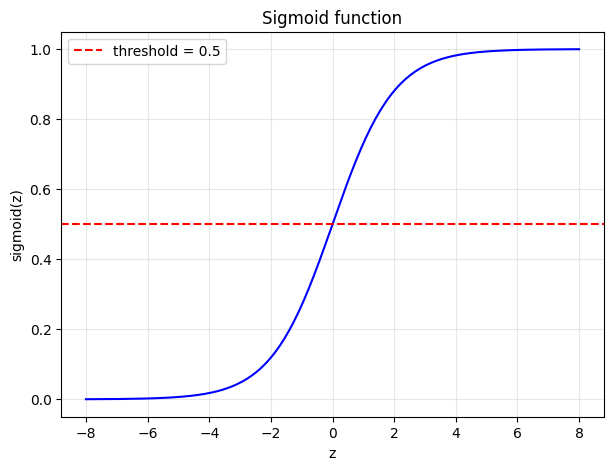

In [71]:
z = np.linspace(-8, 8, 200)
sigmoid = 1 / (1 + np.exp(-z))

plt.figure(figsize=(7, 5))
plt.plot(z, sigmoid, color='blue')
plt.axhline(0.5, color='red', linestyle='--', label='threshold = 0.5')
plt.xlabel('z')
plt.ylabel('sigmoid(z)')
plt.title('Sigmoid function')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**3. What is the role of the probability threshold?**
The model gives a probability, and the threshold is the cut-off used to turn it into a class label. With a threshold of 0.5 (the default), any row with probability of 0.5 or more is predicted as High Sales and the rest as Low Sales. Changing the threshold changes the balance between false positives and false negatives.

**4. What is the difference between Linear Regression and Logistic Regression?**

| | Linear Regression | Logistic Regression |
|---|---|---|
| Output | Continuous value (e.g. sales = 17.3) | Probability, then a class (High / Low) |
| Problem type | Regression | Classification |
| Function used | Straight line | Sigmoid applied to a linear combination |
| Evaluation | MAE, MSE, RMSE, R2 | Accuracy, precision, recall, F1, confusion matrix |

**5. What happens if the threshold is changed from 0.5 to 0.7?**
The model becomes stricter about calling something High Sales. Only rows with a probability of at least 0.7 are labelled High. Usually this gives fewer false positives (higher precision) but more false negatives (lower recall). Let me check it on our data:

In [72]:
yc_pred_07 = (yc_prob >= 0.7).astype(int)

print("Confusion matrix at threshold 0.7")
print(confusion_matrix(yc_test, yc_pred_07))
print()

thr_results = pd.DataFrame(
    {'Threshold 0.5': [accuracy_score(yc_test, yc_pred), precision_score(yc_test, yc_pred),
                       recall_score(yc_test, yc_pred), f1_score(yc_test, yc_pred)],
     'Threshold 0.7': [accuracy_score(yc_test, yc_pred_07), precision_score(yc_test, yc_pred_07),
                       recall_score(yc_test, yc_pred_07), f1_score(yc_test, yc_pred_07)]},
    index=['Accuracy', 'Precision', 'Recall', 'F1-score'])
thr_results.round(4)

Confusion matrix at threshold 0.7
[[24  1]
 [ 2 13]]



,Threshold 0.5,Threshold 0.7
Accuracy,0.8750,0.9250
Precision,0.8125,0.9286
Recall,0.8667,0.8667
F1-score,0.8387,0.8966


With 0.7, the false positives dropped from 3 to 1, so precision went up (0.81 to 0.93), while recall stayed the same at 0.87 (13 of 15 high sales still found). Overall accuracy also went up, from 87.5% to 92.5%. In general a higher threshold trades recall for precision, and here it happened to cost us nothing on this small test set of 40 rows. I would not read too much into this one result, because a different split could behave differently.

**6. How would a company use this model to plan its advertising budget?**
The company can enter a planned budget split (TV, Radio, Newspaper) and the model will give the probability that sales will be High. It can then compare different budget plans and choose the cheapest one that gives a high probability of reaching the sales target of 15 or more. The coefficients show that TV and Radio push the probability up while Newspaper has almost no effect, so money can be shifted away from newspaper towards TV and Radio. The threshold can be adjusted based on how risk averse the company is, for example a higher threshold if it wants to be sure before committing a big budget.

---
# Part F: Comparative Analysis and Business Interpretation

## Q11. Final answers

In [73]:
# summary of the results from all the models
summary_table = pd.DataFrame({
    'Model': ['Simple Linear (TV)', 'Multiple Linear (TV, Radio, Newspaper)',
              'Polynomial degree 2 (TV)', 'Polynomial degree 3 (TV)'],
    'Test R2': [r2_score(y_test_tv, y_pred_tv), r2_score(y_test, y_pred_mlr),
                r2_score(y_test_tv, y_test_pred2), r2_score(y_test_tv, y_test_pred3)],
    'Test RMSE': [np.sqrt(mean_squared_error(y_test_tv, y_pred_tv)),
                  np.sqrt(mean_squared_error(y_test, y_pred_mlr)),
                  np.sqrt(mean_squared_error(y_test_tv, y_test_pred2)),
                  np.sqrt(mean_squared_error(y_test_tv, y_test_pred3))]})
summary_table.round(4)

,Model,Test R2,Test RMSE
0,Simple Linear (TV),0.6767,3.1945
1,"Multiple Linear (TV, Radio, Newspaper)",0.8994,1.7816
2,Polynomial degree 2 (TV),0.6825,3.1655
3,Polynomial degree 3 (TV),0.6695,3.2296


**1. Compare Linear Regression, Polynomial Regression and Logistic Regression.**
Linear and polynomial regression both predict an actual sales number. Linear uses a straight line, polynomial allows a curve. In our data the polynomial models (degree 2 and 3) gave almost the same accuracy as the straight line when using TV alone (R2 around 0.67 to 0.68), so the extra complexity was not worth it. Multiple linear regression using all three media did much better (R2 0.90). Logistic regression is different because it predicts a class (High or Low sales), not a number, and it reached about 88% accuracy at the 0.5 threshold. It cannot be compared directly to the other two with R2, since they solve different kinds of problems.

**2. Which model is suitable for predicting continuous sales values?**
Multiple Linear Regression, since it has the lowest error (RMSE 1.78) and the highest R2 (0.90) among the regression models.

**3. Which model is suitable for predicting High Sales or Low Sales?**
Logistic Regression, because the target is a binary category.

**4. Which advertising medium should a company prioritize?**
TV first, then Radio. TV has the highest correlation with sales (0.78) and the largest effect in the multiple regression once scale is taken into account. Radio is second, and it is cheaper to gain from since each unit of radio spend has a larger raw coefficient (0.19 vs 0.045 for TV). Newspaper should get the lowest priority.

**5. Is newspaper advertising expenditure useful for predicting sales?**
Not really. Its correlation with sales is weak (0.23), and in the multiple regression its coefficient is about 0.003, which is practically zero. The weak correlation that exists is probably because Newspaper is correlated with Radio (0.35), not because newspaper ads themselves drive sales. Dropping it would barely change the model.

**6. Can increasing advertising expenditure guarantee higher sales?**
No. The models only describe an average relationship, and the scatter plots show a lot of spread around the lines (the TV only model leaves about 32% of the variation unexplained). Other things like pricing, season, competition and product quality also affect sales. The extra gain from spending can also shrink at higher budgets.

**7. What are the limitations of your developed models?**

- The dataset is small (200 rows, only 40 in the test set), so the metrics can change noticeably with a different random split.
- Only three predictors are used. Factors like price, season, competitors and region are missing.
- Linear regression assumes a straight line relationship and independent effects, so it cannot capture interactions between media (for example TV and Radio working together).
- Newspaper has 2 outliers that were left in the data.
- The classification threshold of 15 is arbitrary, and rows close to 15 are hard to classify correctly.
- The models show association, not cause and effect.
- Results were based on a single train/test split with no cross validation.

**8. Suggest two ways to improve the models.**

1. Add an interaction term between TV and Radio (TV x Radio) or use more variables. The scatter plots suggest that TV and Radio together may boost sales more than the sum of their separate effects, and this would also be a cheap way to capture more of the remaining 10% unexplained variation.
2. Use k-fold cross validation instead of a single split, and collect more data. This would give more reliable performance estimates, and for the logistic model it would help in choosing the best threshold for the business need.